# Cuaderno de modelos de regresión y clasificación
**EVI1-U2 · Guías G-09 a G-12 · Unidad II**

**Universidad Nacional del Altiplano – Puno**  
Facultad de Ingeniería Mecánica Eléctrica, Electrónica y Sistemas  
Escuela Profesional de Ingeniería de Sistemas

**Curso:** Análisis de Datos (SIS323) · **Semestre:** 2026-II  
**Docente:** Fredy Collanqui Martinez · **Fecha:** 24 de noviembre de 2026

| Integrantes | Código |
|---|---|
| Mamani Zapana Edward | 229678 |
| Mamani Panca Roger Golber | 228917 |
| Gutierrez Arratia Kevin Diego | 227983 |

## Presentación
El estudio integra dos aplicaciones del análisis de datos: la estimación del alquiler mensual de departamentos de Puno y Juliaca y la detección de clientes con riesgo de abandonar un proveedor de internet. Se comparan modelos por su capacidad de generalizar y se interpretan sus resultados para apoyar decisiones inmobiliarias y comerciales.

El desarrollo comprende la preparación de los datos, la regresión simple y sus residuos, la regresión múltiple, la comparación de clasificadores y la evaluación del modelo final según el costo de sus errores.

## 1. Datos y metodología
Se emplean `alquileres_puno_juliaca.csv` y `clientes_isp.csv`, proporcionados para las prácticas del curso. El primero contiene 320 departamentos y el segundo 900 clientes. La unidad de análisis es un departamento para la regresión y un cliente para la clasificación.

La **semilla 42** se mantiene en todas las divisiones aleatorias. Los datos de prueba se reservan para la evaluación final. La codificación de categorías y el escalado se ajustan dentro de cada entrenamiento, incluidas las particiones de validación cruzada.

### 1.1. Carga y exploración

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def tabla(filas, columnas=None):
    df = filas if isinstance(filas, pd.DataFrame) else pd.DataFrame(filas, columns=columnas)
    display(df.style.format(precision=3))
    return df

In [2]:
# Los CSV se leen desde el directorio de trabajo o desde la carpeta datos.
def cargar_csv(nombre):
    ruta = Path(nombre)
    if not ruta.is_file():
        ruta = Path('datos') / nombre
    return pd.read_csv(ruta)

alq = cargar_csv('alquileres_puno_juliaca.csv')
isp = cargar_csv('clientes_isp.csv')

resumen_datos = pd.DataFrame({
    'Conjunto': ['Alquileres', 'Clientes ISP'],
    'Registros': [len(alq), len(isp)],
    'Variables': [alq.shape[1], isp.shape[1]],
    'Valores faltantes': [alq.isna().sum().sum(), isp.isna().sum().sum()],
    'Filas duplicadas': [alq.duplicated().sum(), isp.duplicated().sum()]
})
tabla(resumen_datos)
display(alq.head(3), isp.head(3))

,Conjunto,Registros,Variables,Valores faltantes,Filas duplicadas
0,Alquileres,320,9,0,0
1,Clientes ISP,900,9,0,0


,ciudad,area_m2,habitaciones,banos,distancia_centro_km,antiguedad_anios,cochera,internet_fibra,precio_soles
0,Puno,86,3,2,5.8,20,Sí,No,1030
1,Juliaca,109,3,1,2.2,15,No,No,1040
2,Puno,77,4,2,0.3,4,No,No,1090


,cliente_id,zona,plan_mbps,meses_antiguedad,cortes_ultimo_mes,reclamos_6_meses,pago_puntual,precio_mensual,baja
0,C00001,Urbana,10,41,2,0,No,59,0
1,C00002,Rural,100,39,4,4,Sí,159,0
2,C00003,Urbana,100,50,0,0,Sí,149,0


### 1.2. Variables y calidad de los datos
No se encontraron valores faltantes ni filas completamente duplicadas; se conservaron todos los registros.

| Aplicación | Variable objetivo | Variables explicativas |
|---|---|---|
| Alquileres | `precio_soles`: alquiler mensual en soles | Área (m²), habitaciones, baños, distancia al centro (km), antigüedad (años), ciudad, cochera e internet por fibra |
| Clientes ISP | `baja`: 1 abandona y 0 continúa | Zona, velocidad del plan (Mbps), antigüedad (meses), cortes del último mes, reclamos de los últimos seis meses, pago puntual y precio mensual |

`cliente_id` identifica al cliente y se excluye de las predictoras. Los alquileres corresponden a datos simulados según G-09. Para ISP se supone que las características se conocen antes de la baja; el archivo no incluye fechas que permitan comprobar esa secuencia temporal. Las asociaciones de ambos modelos no se interpretan como relaciones causales.

## 2. Regresión lineal simple · G-09
### 2.1. Relación entre el área y el alquiler
Se ajusta una recta que estima el alquiler mensual a partir del área. Este primer análisis utiliza los 320 departamentos y tiene carácter descriptivo. En la sección 3 se reentrena el modelo sobre una muestra de entrenamiento para evaluar su desempeño en departamentos no utilizados en el ajuste.

precio estimado (S/) = 170.61 + 10.18 × área (m²)
Pearson: 0.817; media del residuo: 0.000000; desviación muestral: S/ 127.03


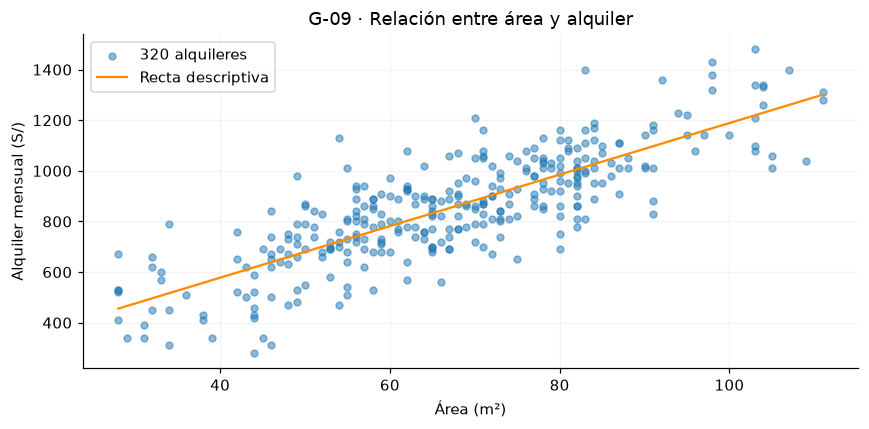

In [3]:
Xs = alq[['area_m2']]
yr = alq['precio_soles']
simple_descriptivo = LinearRegression().fit(Xs, yr)
b0, b1 = simple_descriptivo.intercept_, simple_descriptivo.coef_[0]
ajustados = simple_descriptivo.predict(Xs)
residuos = yr - ajustados
corr = alq.area_m2.corr(yr)
mae_descriptivo = mean_absolute_error(yr, ajustados)
p60, p85 = simple_descriptivo.predict(pd.DataFrame({'area_m2': [60,85]}))
print(f'precio estimado (S/) = {b0:.2f} + {b1:.2f} × área (m²)')
print(f'Pearson: {corr:.3f}; media del residuo: {residuos.mean():.6f}; desviación muestral: S/ {residuos.std(ddof=1):.2f}')
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(alq.area_m2, yr, alpha=.5, s=20, label='320 alquileres')
orden = np.argsort(alq.area_m2.to_numpy())
ax.plot(alq.area_m2.iloc[orden], ajustados[orden], color='darkorange', label='Recta descriptiva')
ax.set(xlabel='Área (m²)', ylabel='Alquiler mensual (S/)', title='G-09 · Relación entre área y alquiler')
ax.legend(); ax.grid(alpha=.15); plt.tight_layout(); plt.show()

### 2.2. Interpretación de los coeficientes
La ecuación estimada es **alquiler mensual = 170.61 + 10.18 × área**, con el alquiler expresado en soles y el área en metros cuadrados. La correlación de Pearson es **0.817**, lo que describe una asociación lineal positiva entre ambas variables.

La pendiente indica que un metro cuadrado adicional se asocia, en promedio, con **S/ 10.18 más de alquiler mensual**. La intersección de S/ 170.61 corresponde al valor matemático para un área de cero metros cuadrados; no representa una cotización comercial válida.

Para 60 m² se estima **S/ 781.53** y para 85 m², **S/ 1036.08**. Los avisos de S/ 800 y S/ 1100 superan esas estimaciones en S/ 18.47 y S/ 63.92, respectivamente. Son diferencias menores que el error absoluto medio del ajuste, aunque esta comparación por sí sola no demuestra que los precios sean adecuados.

### 2.3. Análisis de residuos

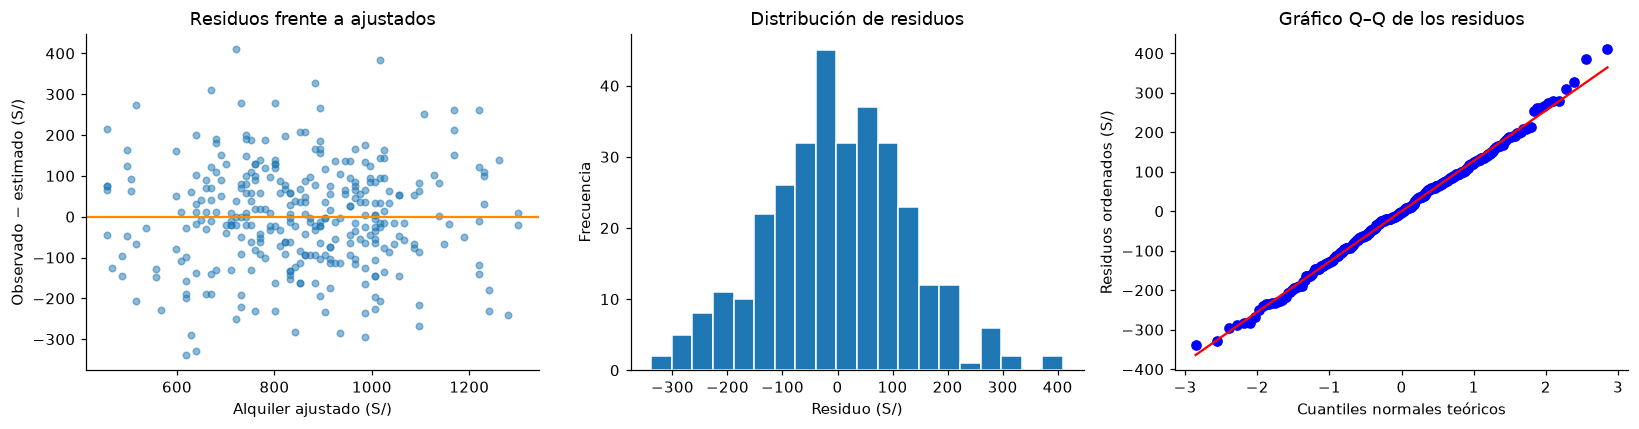

,count,mean,std
tramo,,,
"(455.706, 730.623]",83,-8.101,144.942
"(730.623, 852.807]",78,10.271,115.151
"(852.807, 985.174]",84,-1.467,118.505
"(985.174, 1300.818]",75,-0.074,128.625


Asimetría muestral: 0.053. Un residuo positivo significa que la recta subestimó el alquiler.


In [4]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].scatter(ajustados, residuos, alpha=.5, s=18)
axes[0].axhline(0, color='darkorange')
axes[0].set(xlabel='Alquiler ajustado (S/)', ylabel='Observado − estimado (S/)', title='Residuos frente a ajustados')
axes[1].hist(residuos,bins=20,edgecolor='white')
axes[1].set(xlabel='Residuo (S/)',ylabel='Frecuencia',title='Distribución de residuos')
stats.probplot(residuos,dist='norm',plot=axes[2])
axes[2].set(title='Gráfico Q–Q de los residuos',xlabel='Cuantiles normales teóricos',ylabel='Residuos ordenados (S/)')
plt.tight_layout(); plt.show()
resumen_residuos = pd.DataFrame({'ajustado':ajustados,'residuo':residuos})
resumen_residuos['tramo'] = pd.qcut(resumen_residuos.ajustado,4)
diagnostico = resumen_residuos.groupby('tramo', observed=True).residuo.agg(['count','mean','std'])
tabla(diagnostico)
print(f'Asimetría muestral: {residuos.skew():.3f}. Un residuo positivo significa que la recta subestimó el alquiler.')

El residuo se define como **precio observado menos precio estimado**. Un residuo positivo significa que el modelo subestimó el alquiler; uno negativo indica sobreestimación.

La nube de residuos no presenta una curvatura sistemática marcada, por lo que la recta constituye una aproximación razonable. La dispersión no es idéntica en todo el rango: las desviaciones por cuartiles de alquiler ajustado van de **S/ 115.15 a S/ 144.94**. No se observa un embudo pronunciado, pero la inspección gráfica no demuestra varianza constante.

El histograma es aproximadamente simétrico, con asimetría **0.053**. El gráfico Q–Q muestra proximidad a la recta en la zona central y algunos apartamientos en las colas. La normalidad es una aproximación, no una propiedad demostrada. La independencia tampoco puede comprobarse sin conocer el diseño de generación o muestreo.

La media residual cercana a cero es una propiedad del ajuste con intersección sobre la misma muestra. La desviación muestral de los residuos es **S/ 127.03** y el MAE es **S/ 99.95**. Estas cifras describen errores dentro de los datos utilizados para ajustar la recta.

### 2.4. Implicación para la inmobiliaria
El modelo ofrece una referencia inicial de alquiler para áreas entre **28 y 111 m²**. Su utilidad es limitada porque omite ciudad, baños, habitaciones, distancia al centro, antigüedad, cochera y fibra. Incorporar estas características permite evaluar si las cotizaciones mejoran en nuevos departamentos.

## 3. Regresión lineal múltiple · G-10
### 3.1. Entrenamiento, codificación y validación
Se utiliza `precio_soles` como objetivo y las ocho características del inmueble como predictoras. La división es **80 % para entrenamiento (256 departamentos) y 20 % para prueba (64)**, con `random_state=42`. Los modelos simple y múltiple utilizan exactamente las mismas filas.

Las variables categóricas se codifican con `OneHotEncoder(drop='first')`. Las referencias son **Juliaca**, **sin cochera** y **sin fibra**. El modelo se ajusta mediante `LinearRegression` de Scikit-learn.

La validación cruzada utiliza cinco particiones de entrenamiento con `KFold(shuffle=True, random_state=42)`. Se elige el modelo con menor RMSE medio de validación y se evalúa posteriormente en prueba. El RMSE expresa el error en soles y penaliza errores grandes; R² mide la variabilidad explicada y MAE resume la diferencia absoluta media.

In [5]:
num_r = ['area_m2','habitaciones','banos','distancia_centro_km','antiguedad_anios']
cat_r = ['ciudad','cochera','internet_fibra']
Xr = alq.drop(columns='precio_soles')
Xr_ent, Xr_pru, yr_ent, yr_pru = train_test_split(Xr, yr, test_size=.2, random_state=SEMILLA)
assert set(Xr_ent.index).isdisjoint(Xr_pru.index)
pre_r = ColumnTransformer([
    ('num','passthrough',num_r),
    ('cat',OneHotEncoder(drop='first',handle_unknown='error',sparse_output=False),cat_r)
], verbose_feature_names_out=False)
regresores = {
 'Simple (área)': Pipeline([('area',ColumnTransformer([('area','passthrough',['area_m2'])])),('modelo',LinearRegression())]),
 'Múltiple': Pipeline([('preparacion',pre_r),('modelo',LinearRegression())])
}
cv_r = KFold(n_splits=5,shuffle=True,random_state=SEMILLA)
cv_reg = {}
for nombre, m in regresores.items():
    cv = cross_validate(m,Xr_ent,yr_ent,cv=cv_r,scoring={'r2':'r2','mse':'neg_mean_squared_error'},n_jobs=1)
    cv_reg[nombre] = {'r2':cv['test_r2'], 'rmse':np.sqrt(-cv['test_mse'])}
elegido_r = min(cv_reg, key=lambda n: cv_reg[n]['rmse'].mean())
print('Modelo elegido antes de evaluar la prueba:',elegido_r)
filas_reg=[]
for nombre, m in regresores.items():
    m.fit(Xr_ent,yr_ent)
    pred=m.predict(Xr_pru)
    filas_reg.append({'Modelo':nombre,'R² prueba':r2_score(yr_pru,pred),'RMSE prueba (S/)':np.sqrt(mean_squared_error(yr_pru,pred)),
        'MAE prueba (S/)':mean_absolute_error(yr_pru,pred),'CV R² media':cv_reg[nombre]['r2'].mean(),
        'CV R² desv.':cv_reg[nombre]['r2'].std(ddof=0),'CV RMSE media (S/)':cv_reg[nombre]['rmse'].mean(),
        'CV RMSE desv. (S/)':cv_reg[nombre]['rmse'].std(ddof=0)})
tabla_reg = pd.DataFrame(filas_reg).set_index('Modelo')
cv_detalle = pd.DataFrame([{'Modelo':n,'Pliegue':i+1,'R²':r,'RMSE (S/)':e}
    for n,v in cv_reg.items() for i,(r,e) in enumerate(zip(v['r2'],v['rmse']))])
tabla(cv_detalle)

Modelo elegido antes de evaluar la prueba: Múltiple


,Modelo,Pliegue,R²,RMSE (S/)
0,Simple (área),1,0.406,154.369
1,Simple (área),2,0.630,131.759
2,Simple (área),3,0.677,120.778
3,Simple (área),4,0.637,122.110
4,Simple (área),5,0.769,122.614
5,Múltiple,1,0.811,86.999
6,Múltiple,2,0.851,83.488
7,Múltiple,3,0.788,97.774
8,Múltiple,4,0.788,93.468
9,Múltiple,5,0.888,85.236


,Modelo,Pliegue,R²,RMSE (S/)
0,Simple (área),1,0.405970,154.368591
1,Simple (área),2,0.629979,131.759428
2,Simple (área),3,0.676934,120.778099
3,Simple (área),4,0.637456,122.110488
4,Simple (área),5,0.769004,122.614170
5,Múltiple,1,0.811321,86.999471
6,Múltiple,2,0.851438,83.487751
7,Múltiple,3,0.788280,97.773929
8,Múltiple,4,0.787589,93.467667
9,Múltiple,5,0.888372,85.236426


### 3.2. Comparación de resultados

In [6]:
tabla(tabla_reg)

,R² prueba,RMSE prueba (S/),MAE prueba (S/),CV R² media,CV R² desv.,CV RMSE media (S/),CV RMSE desv. (S/)
Modelo,,,,,,,
Simple (área),0.707,118.668,91.434,0.624,0.120,130.326,12.635
Múltiple,0.838,88.153,71.996,0.825,0.039,89.393,5.380


,R² prueba,RMSE prueba (S/),MAE prueba (S/),CV R² media,CV R² desv.,CV RMSE media (S/),CV RMSE desv. (S/)
Modelo,,,,,,,
Simple (área),0.706600,118.668286,91.433955,0.623868,0.119651,130.326155,12.635112
Múltiple,0.838095,88.152576,71.996299,0.825400,0.039113,89.393049,5.379980


El modelo múltiple obtiene **R² = 0.838** y **RMSE = S/ 88.15** en prueba, frente a R² = 0.707 y RMSE = S/ 118.67 del modelo simple. La reducción del RMSE es **S/ 30.52**.

Un R² de 0.838 equivale a reducir aproximadamente el 83.8% del error cuadrático respecto al promedio de los precios de prueba como referencia matemática. No representa un porcentaje de alquileres acertados. El MAE múltiple de **S/ 72.00** es la diferencia absoluta media entre cotización y precio observado.

El precio medio de prueba es **S/ 843.12**. El RMSE múltiple equivale al **10.5%** de ese promedio; esta razón no es un error porcentual por inmueble. En validación, el múltiple alcanza R² medio de **0.825 ± 0.039**, con menor RMSE medio y menor variación entre pliegues que el simple. Se recomienda el modelo múltiple como apoyo para la cotización.

### 3.3. Coeficientes del modelo múltiple

In [7]:
mult = regresores['Múltiple']
nombres_r = mult.named_steps['preparacion'].get_feature_names_out()
coef_r = pd.Series(mult.named_steps['modelo'].coef_, index=nombres_r)
tabla(coef_r.rename('Coeficiente (S/)').to_frame())
print(f'Intersección: S/ {mult.named_steps["modelo"].intercept_:.2f}')

,Coeficiente (S/)
area_m2,9.420
habitaciones,2.501
banos,64.234
distancia_centro_km,-45.300
antiguedad_anios,-2.827
ciudad_Puno,74.566
cochera_Sí,76.293
internet_fibra_Sí,61.499


Intersección: S/ 176.90


Manteniendo constantes las demás características, cada m² adicional se asocia con **S/ 9.42** más de alquiler; una habitación adicional, con **S/ 2.50**; y un baño adicional, con **S/ 64.23**. Cada kilómetro de distancia al centro se asocia con una reducción de **S/ 45.30**, y cada año de antigüedad, con una reducción de **S/ 2.83**.

La ubicación en Puno presenta una diferencia estimada de **S/ 74.57** respecto a Juliaca. Tener cochera se asocia con **S/ 76.29** más que no tenerla, y contar con fibra, con **S/ 61.50** adicionales.

La intersección de S/ 176.90 corresponde a las categorías de referencia y a todas las variables numéricas en cero, una combinación sin interpretación comercial habitual. Los coeficientes describen asociaciones condicionadas; no prueban causalidad ni significación estadística. El coeficiente pequeño de habitaciones puede relacionarse con la información que comparte con el área.

### 3.4. Errores en los departamentos de prueba

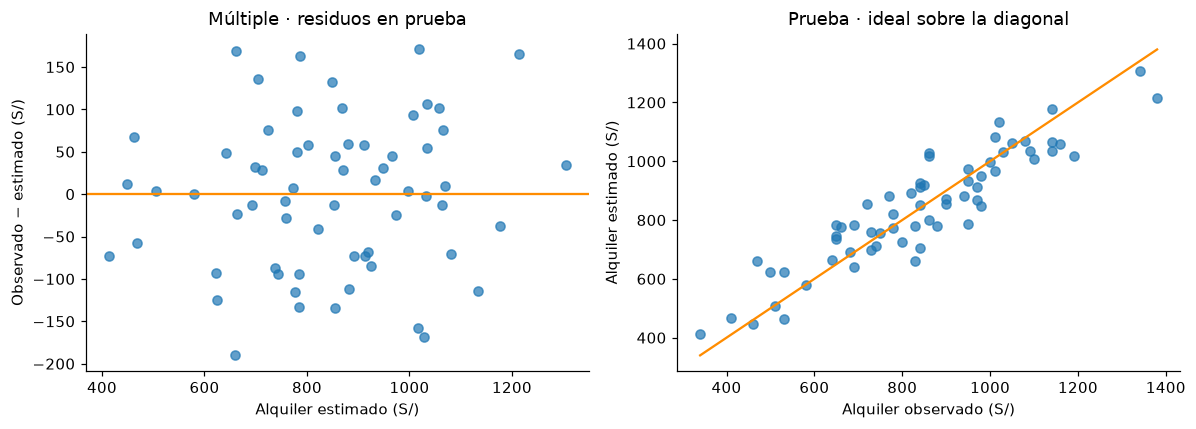

In [8]:
pred_r = mult.predict(Xr_pru)
res_r = yr_pru - pred_r
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(pred_r,res_r,alpha=.7)
ax[0].axhline(0,color='darkorange')
ax[0].set(xlabel='Alquiler estimado (S/)',ylabel='Observado − estimado (S/)',title='Múltiple · residuos en prueba')
ax[1].scatter(yr_pru,pred_r,alpha=.7)
limites=[min(yr_pru.min(),pred_r.min()),max(yr_pru.max(),pred_r.max())]
ax[1].plot(limites,limites,color='darkorange')
ax[1].set(xlabel='Alquiler observado (S/)',ylabel='Alquiler estimado (S/)',title='Prueba · ideal sobre la diagonal')
plt.tight_layout();plt.show()

El residuo medio en prueba es **S/ -0.61**, lo que indica una ligera sobreestimación promedio. Los errores observados van de **S/ -190.15 a S/ 170.67**. Este rango no garantiza el comportamiento de un inmueble futuro. La cotización debe complementarse con revisión comercial, especialmente para características poco representadas o cambios del mercado.

## 4. Comparación de clasificadores · G-11
### 4.1. Preparación y modelos
La variable objetivo es `baja`; la **clase positiva (1)** corresponde a un cliente que abandona el servicio. Se realiza una división **75 % / 25 %**, estratificada por la clase objetivo y con semilla 42: **675 clientes de entrenamiento y 225 de prueba**.

Se comparan regresión logística, árbol de decisión con profundidad máxima 3 y KNN con 5 vecinos. Las categorías de referencia son zona Rural y pago puntual No. Logística y KNN utilizan `StandardScaler` dentro de sus pipelines; el árbol no requiere escalado. Un árbol sin límite de profundidad sirve como diagnóstico de sobreajuste.

La selección comercial prioriza **recall**, porque omitir una baja supone perder una oportunidad de retención. El umbral y el modelo se seleccionan con predicciones de cinco pliegues estratificados exclusivamente de entrenamiento. Se comparan los umbrales logísticos 0.5, 0.4, 0.3 y 0.2 y las reglas estándar del árbol y KNN; los empates se resuelven por precisión y F1. La sección 5 desarrolla su evaluación.

In [9]:
Xc = isp.drop(columns=['cliente_id','baja'])
yc = isp.baja
num_c = ['plan_mbps','meses_antiguedad','cortes_ultimo_mes','reclamos_6_meses','precio_mensual']
cat_c = ['zona','pago_puntual']
Xc_ent,Xc_pru,yc_ent,yc_pru = train_test_split(Xc,yc,test_size=.25,stratify=yc,random_state=SEMILLA)
assert set(Xc_ent.index).isdisjoint(Xc_pru.index)

def preparar_c():
    return ColumnTransformer([
      ('num','passthrough',num_c),
      ('cat',OneHotEncoder(drop='first',handle_unknown='error',sparse_output=False),cat_c)
    ],verbose_feature_names_out=False)

modelos = {
 'Regresión logística':Pipeline([('preparacion',preparar_c()),('escala',StandardScaler()),('modelo',LogisticRegression(max_iter=2000,random_state=SEMILLA))]),
 'Árbol (profundidad 3)':Pipeline([('preparacion',preparar_c()),('modelo',DecisionTreeClassifier(max_depth=3,random_state=SEMILLA))]),
 'KNN (k=5)':Pipeline([('preparacion',preparar_c()),('escala',StandardScaler()),('modelo',KNeighborsClassifier(n_neighbors=5))])}
arbol_libre = Pipeline([('preparacion',preparar_c()),('modelo',DecisionTreeClassifier(random_state=SEMILLA))])
base = DummyClassifier(strategy='constant',constant=0).fit(Xc_ent,yc_ent)

def metricas_clf(y,pred):
    vn,fp,fn,vp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'VP':int(vp),'FP':int(fp),'FN':int(fn),'VN':int(vn),
      'Exactitud':accuracy_score(y,pred),'Precisión':precision_score(y,pred,pos_label=1,zero_division=0),
      'Recall':recall_score(y,pred,pos_label=1,zero_division=0),'F1':f1_score(y,pred,pos_label=1,zero_division=0),
      'Clientes a llamar':int(np.sum(pred))}

# Predicciones fuera de pliegue (OOF): cada cliente de entrenamiento se evalúa
# con un modelo que no se ajustó con ese cliente. La prueba no participa.
cv_c = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEMILLA)
filas_validacion=[]
for nombre,m in modelos.items():
    if nombre=='Regresión logística':
        prob_oof = cross_val_predict(m,Xc_ent,yc_ent,cv=cv_c,method='predict_proba',n_jobs=1)[:,1]
        for u in [.5,.4,.3,.2]:
            filas_validacion.append({'Modelo':nombre,'Umbral':u,**metricas_clf(yc_ent,(prob_oof>=u).astype(int))})
    else:
        pred_oof = cross_val_predict(m,Xc_ent,yc_ent,cv=cv_c,method='predict',n_jobs=1)
        filas_validacion.append({'Modelo':nombre,'Umbral':.5,**metricas_clf(yc_ent,pred_oof)})
validacion = pd.DataFrame(filas_validacion)
mejor = validacion.sort_values(['Recall','Precisión','F1'],ascending=False,kind='stable').iloc[0]
MODELO_FINAL, UMBRAL_FINAL = str(mejor['Modelo']),float(mejor['Umbral'])
print(f'Decisión fijada con entrenamiento: {MODELO_FINAL}, umbral {UMBRAL_FINAL:.1f}; recall OOF = {mejor["Recall"]:.3f}')
for m in modelos.values(): m.fit(Xc_ent,yc_ent)
arbol_libre.fit(Xc_ent,yc_ent);

Decisión fijada con entrenamiento: Regresión logística, umbral 0.2; recall OOF = 0.753


### 4.2. Balance de clases y línea base
De los 900 clientes, **205 (22.8%)** presentan baja. La proporción se conserva aproximadamente en entrenamiento (**22.8%**) y prueba (**22.7%**).

Predecir siempre «continúa» obtiene **77.3% de exactitud** en prueba, pero no detecta ninguna de las 51 bajas. Esta línea base permite mostrar por qué una exactitud elevada no basta para evaluar la utilidad comercial.

### 4.3. Exactitud y sobreajuste

In [10]:
filas_exactitud=[]
for nombre,m in {'Línea base (continúa)':base,**modelos,'Árbol sin límite (diagnóstico)':arbol_libre}.items():
    ent,pru=m.score(Xc_ent,yc_ent),m.score(Xc_pru,yc_pru)
    brecha=ent-pru
    if nombre.startswith('Línea'): lectura='Referencia: no detecta ninguna baja.'
    elif nombre.startswith('Árbol sin'): lectura='La exactitud casi perfecta en entrenamiento y su caída en prueba evidencian sobreajuste.'
    else: lectura=f'Brecha de {100*brecha:.1f} puntos porcentuales; una sola partición no permite demostrar ausencia de sobreajuste.'
    filas_exactitud.append({'Modelo':nombre,'Exactitud entrenamiento':ent,'Exactitud prueba':pru,'Brecha':brecha,
       '¿Supera base en prueba?':'Sí' if pru>base.score(Xc_pru,yc_pru) else 'No','Interpretación':lectura})
exactitud = pd.DataFrame(filas_exactitud)
tabla(exactitud.drop(columns='Interpretación'))

,Modelo,Exactitud entrenamiento,Exactitud prueba,Brecha,¿Supera base en prueba?
0,Línea base (continúa),0.772,0.773,-0.001,No
1,Regresión logística,0.815,0.782,0.033,Sí
2,Árbol (profundidad 3),0.813,0.760,0.053,No
3,KNN (k=5),0.828,0.747,0.081,No
4,Árbol sin límite (diagnóstico),0.997,0.733,0.264,No


,Modelo,Exactitud entrenamiento,Exactitud prueba,Brecha,¿Supera base en prueba?
0,Línea base (continúa),0.771852,0.773333,-0.001481,No
1,Regresión logística,0.814815,0.782222,0.032593,Sí
2,Árbol (profundidad 3),0.813333,0.760000,0.053333,No
3,KNN (k=5),0.828148,0.746667,0.081481,No
4,Árbol sin límite (diagnóstico),0.997037,0.733333,0.263704,No


La regresión logística obtiene la mayor exactitud de prueba entre los tres modelos principales, aunque su ventaja respecto a la línea base es pequeña. El árbol sin límite pasa de **0.997** en entrenamiento a **0.733** en prueba, una caída consistente con sobreajuste.

Limitar el árbol a profundidad 3 reduce la brecha entre entrenamiento y prueba. KNN también presenta una pérdida de desempeño al evaluar clientes no usados para el ajuste. Estas diferencias describen la partición analizada; no demuestran por sí solas la ausencia o presencia de sobreajuste en cualquier muestra futura. Para la retención interesa, además, cuántas bajas reales se identifican.

### 4.4. Interpretación de la regresión logística y reglas del árbol

,Predictora,Coeficiente estandarizado,Cambio interpretado,Razón de odds,Lectura comercial
0,plan_mbps,0.290,+28.44 unidades (una desviación de entrenamiento),1.336,"Se asocia con mayor riesgo de baja, manteniendo lo demás constante."
1,meses_antiguedad,-0.796,+17.35 unidades (una desviación de entrenamiento),0.451,"Se asocia con menor riesgo de baja, manteniendo lo demás constante."
2,cortes_ultimo_mes,0.835,+1.29 unidades (una desviación de entrenamiento),2.304,"Se asocia con mayor riesgo de baja, manteniendo lo demás constante."
3,reclamos_6_meses,0.441,+0.93 unidades (una desviación de entrenamiento),1.554,"Se asocia con mayor riesgo de baja, manteniendo lo demás constante."
4,precio_mensual,-0.199,+29.04 unidades (una desviación de entrenamiento),0.819,"Se asocia con menor riesgo de baja, manteniendo lo demás constante."
5,zona_Urbana,0.013,Urbana frente a Rural,1.028,"Se asocia con mayor riesgo de baja, manteniendo lo demás constante."
6,pago_puntual_Sí,-0.267,Sí frente a No,0.505,"Se asocia con menor riesgo de baja, manteniendo lo demás constante."


,Regla exacta,Clientes entrenamiento,Bajas entrenamiento,Proporción de bajas
5,cortes_ultimo_mes > 1.50 Y meses_antiguedad ≤ 21.50 Y cortes_ultimo_mes > 3.50,17,16,0.941
2,cortes_ultimo_mes ≤ 1.50 Y meses_antiguedad > 11.50 Y reclamos_6_meses ≤ 1.50,327,18,0.055


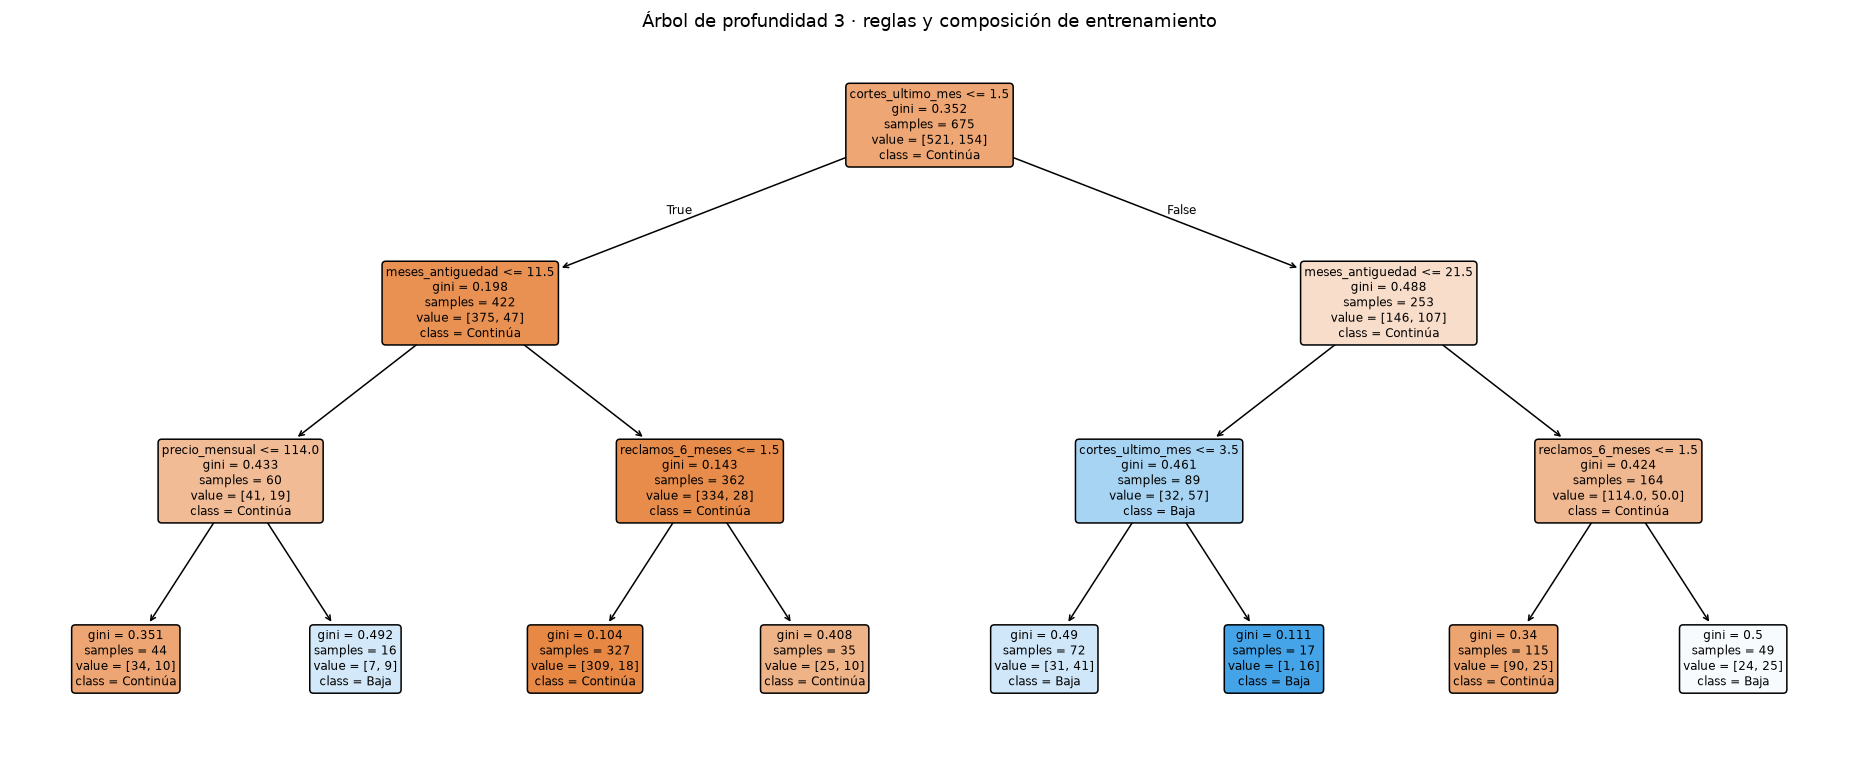

In [11]:
logistica = modelos['Regresión logística']
nombres_c = logistica.named_steps['preparacion'].get_feature_names_out()
coef_c = pd.Series(logistica.named_steps['modelo'].coef_[0],index=nombres_c)
escalas_c = pd.Series(logistica.named_steps['escala'].scale_,index=nombres_c)
filas_coef=[]
for n,c in coef_c.items():
    binaria = n in ['zona_Urbana','pago_puntual_Sí']
    incremento = 1.0 if binaria else float(escalas_c[n])
    efecto_logit = c/escalas_c[n] if binaria else c
    cambio = ('Urbana frente a Rural' if n=='zona_Urbana' else 'Sí frente a No') if binaria else f'+{incremento:.2f} unidades (una desviación de entrenamiento)'
    filas_coef.append([n,c,cambio,np.exp(efecto_logit),
        f'Se asocia con {"mayor" if efecto_logit>0 else "menor"} riesgo de baja, manteniendo lo demás constante.'])
coeficientes_logisticos = tabla(filas_coef,['Predictora','Coeficiente estandarizado','Cambio interpretado','Razón de odds','Lectura comercial'])

arbol = modelos['Árbol (profundidad 3)']
arbol_estimador = arbol.named_steps['modelo']
Xt_arbol = arbol.named_steps['preparacion'].transform(Xc_ent)
hojas = arbol_estimador.apply(Xt_arbol)
t = arbol_estimador.tree_
rutas={}
def recorrer(nodo,condiciones):
    if t.children_left[nodo]==t.children_right[nodo]:
        rutas[nodo]=' Y '.join(condiciones)
        return
    variable=nombres_c[t.feature[nodo]]
    corte=t.threshold[nodo]
    recorrer(t.children_left[nodo],condiciones+[f'{variable} ≤ {corte:.2f}'])
    recorrer(t.children_right[nodo],condiciones+[f'{variable} > {corte:.2f}'])
recorrer(0,[])
reglas = pd.DataFrame([{'Hoja':int(h),'Regla exacta':rutas[h],'Clientes entrenamiento':int((hojas==h).sum()),
    'Bajas entrenamiento':int(yc_ent.to_numpy()[hojas==h].sum()),'Proporción de bajas':float(yc_ent.to_numpy()[hojas==h].mean())}
    for h in np.unique(hojas)]).sort_values('Proporción de bajas',ascending=False)
reglas_elegidas = reglas.iloc[[0,-1]].copy()
reglas_elegidas['Lectura comercial']=['Mayor riesgo observado: priorizar revisión de cortes y contacto preventivo.',
    'Menor riesgo observado: seguimiento habitual, sin suponer que ningún cliente abandonará.']
tabla(reglas_elegidas[['Regla exacta','Clientes entrenamiento','Bajas entrenamiento','Proporción de bajas']])
fig,ax=plt.subplots(figsize=(17,7))
plot_tree(arbol_estimador,feature_names=list(nombres_c),class_names=['Continúa','Baja'],filled=True,rounded=True,fontsize=8,ax=ax)
ax.set_title('Árbol de profundidad 3 · reglas y composición de entrenamiento')
plt.tight_layout();plt.show()

Los cortes recientes y los reclamos se asocian con mayor riesgo de baja; la antigüedad y el pago puntual se asocian con menor riesgo. Los coeficientes de plan y precio describen asociaciones condicionadas por las demás variables. La estimación para zona es cercana a cero, lo que no permite atribuirle un efecto comercial independiente importante en este ajuste.

Los coeficientes logísticos actúan sobre el logaritmo de las *odds*, definidas como probabilidad / (1 − probabilidad). Las variables numéricas se interpretan por una desviación de entrenamiento; para las binarias, la tabla convierte el efecto al cambio completo de categoría. Una razón de odds de 2 no significa duplicar la probabilidad.

La regla de mayor riesgo reúne **16 bajas entre 17 clientes (94.1%)**; la de menor riesgo presenta **18 entre 327 (5.5%)**. Las condiciones exactas permiten al área comercial identificar grupos para revisión preventiva. Son proporciones de entrenamiento; especialmente en grupos pequeños, no deben tratarse como probabilidades futuras garantizadas.

## 5. G-12 · Evaluación de clasificadores
### 5.1. Matrices de confusión y métricas de la clase positiva
En las matrices, **filas = realidad** y **columnas = predicción**, en el orden continúa (0), baja (1):

| Real / Predicción | Continúa (0) | Baja (1) |
|---|---|---|
| Continúa (0) | VN: continúa, no se llama | FP: continúa, se llama innecesariamente |
| Baja (1) | FN: baja no detectada | VP: baja detectada, se propone llamar |

Precisión = VP / (VP + FP); recall = VP / (VP + FN); F1 = 2 × precisión × recall / (precisión + recall). Todas estas métricas se refieren a **baja = 1**. Si no hay positivos predichos, se informa precisión 0 por convención (`zero_division=0`).

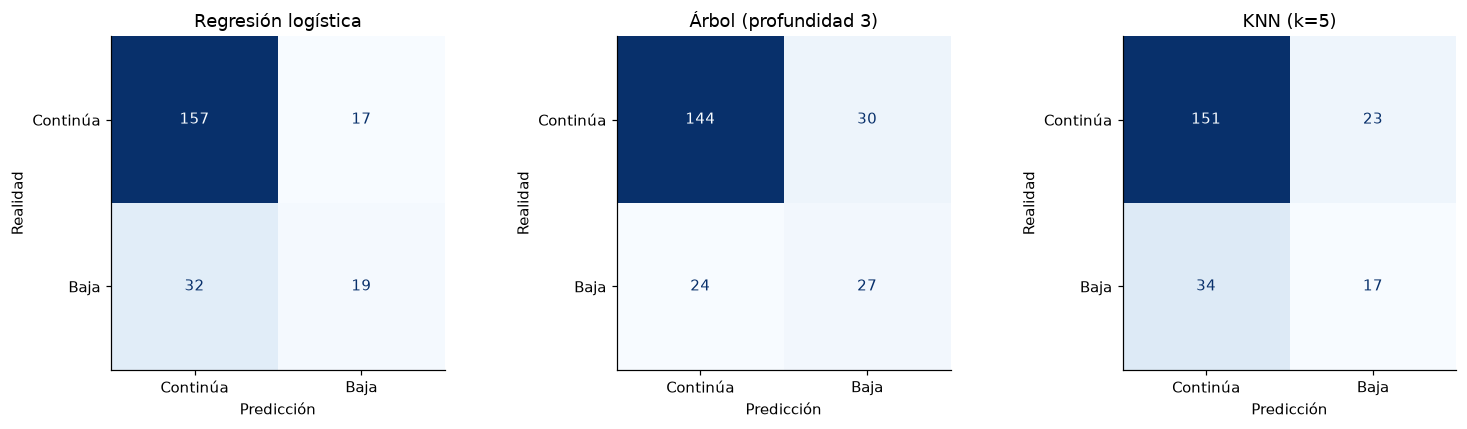

,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar
Modelo,,,,,,,,,
Línea base (continúa),0,0,51,174,0.773,0.000,0.000,0.000,0
Regresión logística,19,17,32,157,0.782,0.528,0.373,0.437,36
Árbol (profundidad 3),27,30,24,144,0.760,0.474,0.529,0.500,57
KNN (k=5),17,23,34,151,0.747,0.425,0.333,0.374,40


In [12]:
filas_prueba=[{'Modelo':'Línea base (continúa)',**metricas_clf(yc_pru,base.predict(Xc_pru))}]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(nombre,m) in zip(axes,modelos.items()):
    pred=m.predict(Xc_pru)
    filas_prueba.append({'Modelo':nombre,**metricas_clf(yc_pru,pred)})
    ConfusionMatrixDisplay(confusion_matrix(yc_pru,pred,labels=[0,1]),display_labels=['Continúa','Baja']).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set(title=nombre,xlabel='Predicción',ylabel='Realidad')
plt.tight_layout();plt.show()
tabla_clf = pd.DataFrame(filas_prueba).set_index('Modelo')
tabla(tabla_clf)
lr = tabla_clf.loc['Regresión logística']
mas_exacto=tabla_clf.drop(index='Línea base (continúa)').Exactitud.idxmax()
mas_recall=tabla_clf.drop(index='Línea base (continúa)').Recall.idxmax()

Con la regla estándar, la regresión logística tiene mayor exactitud (**0.782**), pero el árbol identifica más bajas: recall **0.529**, frente a **0.373** de la logística. Por tanto, el clasificador más exacto no es el que más bajas detecta.

Para la logística, la precisión se comprueba como **19 / (19 + 17) = 0.528**, el recall como **19 / (19 + 32) = 0.373** y F1 como **2 × 19 / (2 × 19 + 17 + 32) = 0.437**. De 36 alertas, 19 corresponden a bajas reales; quedan 32 bajas sin detectar. La línea base omite las 51 bajas de prueba.

### 5.2. Costo de los errores y métrica principal
Un **falso positivo** genera una llamada a un cliente que habría continuado y puede ocasionar un descuento innecesario. Un **falso negativo** omite a un cliente que abandonará, con pérdida de la oportunidad de retención y de ingresos futuros. Bajo el supuesto de que el segundo error es más costoso, la métrica principal es **recall**.

El costo conceptual es **costo de FP × FP + costo de FN × FN**. No se dispone de importes monetarios, capacidad de llamadas ni eficacia de las ofertas, por lo que no se estima ahorro económico. La precisión, F1 y el número de alertas complementan el recall para mostrar la carga comercial.

### 5.3. Selección del umbral con validación cruzada
Cada predicción fuera de pliegue se obtiene con un modelo que no utilizó ese cliente para entrenarse. El siguiente resultado corresponde exclusivamente a entrenamiento; la prueba no interviene en la selección.

In [13]:
tabla(validacion)

,Modelo,Umbral,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar
0,Regresión logística,0.500,58,30,96,491,0.813,0.659,0.377,0.479,88
1,Regresión logística,0.400,73,50,81,471,0.806,0.593,0.474,0.527,123
2,Regresión logística,0.300,89,83,65,438,0.781,0.517,0.578,0.546,172
3,Regresión logística,0.200,116,159,38,362,0.708,0.422,0.753,0.541,275
4,Árbol (profundidad 3),0.500,61,51,93,470,0.787,0.545,0.396,0.459,112
5,KNN (k=5),0.500,44,50,110,471,0.763,0.468,0.286,0.355,94


,Modelo,Umbral,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar
0,Regresión logística,0.5,58,30,96,491,0.813333,0.659091,0.376623,0.479339,88
1,Regresión logística,0.4,73,50,81,471,0.805926,0.593496,0.474026,0.527076,123
2,Regresión logística,0.3,89,83,65,438,0.780741,0.517442,0.577922,0.546012,172
3,Regresión logística,0.2,116,159,38,362,0.708148,0.421818,0.753247,0.540793,275
4,Árbol (profundidad 3),0.5,61,51,93,470,0.786667,0.544643,0.396104,0.458647,112
5,KNN (k=5),0.5,44,50,110,471,0.762963,0.468085,0.285714,0.354839,94


Se selecciona **regresión logística con umbral 0.2** por obtener el mayor recall de validación entre los candidatos: **0.753**, con precisión **0.422** y F1 **0.541**. Produce **275 alertas entre 675 clientes** evaluados fuera de pliegue. Esta estimación se utiliza para elegir la configuración; la evaluación final se realiza en la muestra reservada.

### 5.4. Evaluación de umbrales y modelo final en prueba
Los cuatro umbrales se presentan para describir el intercambio entre detección y llamadas. La elección anterior se mantiene fija. Al reducir el umbral aumenta o se conserva el recall, aunque la precisión no necesariamente cambia de forma monótona.

,Umbral,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar
0,0.500,19,17,32,157,0.782,0.528,0.373,0.437,36
1,0.400,27,21,24,153,0.800,0.562,0.529,0.545,48
2,0.300,31,36,20,138,0.751,0.463,0.608,0.525,67
3,0.200,38,56,13,118,0.693,0.404,0.745,0.524,94


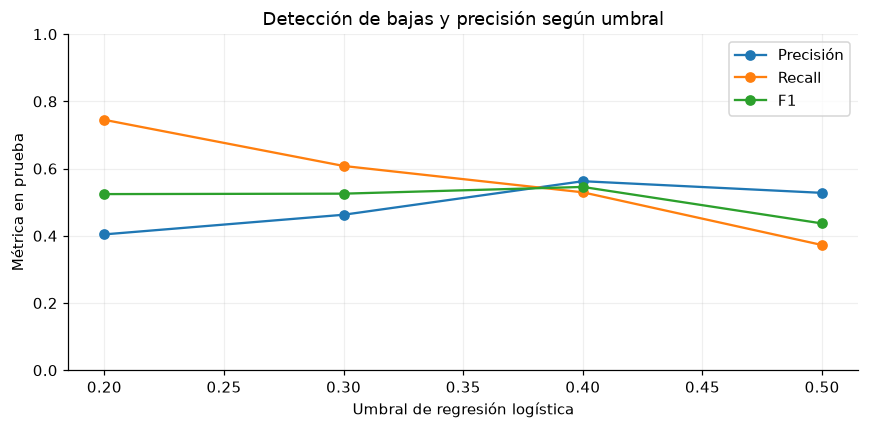

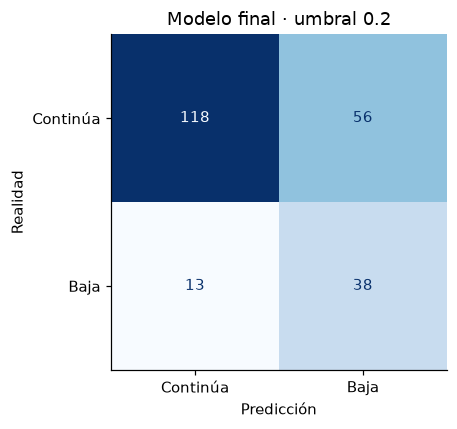

In [14]:
prob_pru=logistica.predict_proba(Xc_pru)[:,1]
umbrales_prueba=pd.DataFrame([{'Umbral':u,**metricas_clf(yc_pru,(prob_pru>=u).astype(int))} for u in [.5,.4,.3,.2]])
tabla(umbrales_prueba)
fig,ax=plt.subplots(figsize=(8,4))
orden_u=umbrales_prueba.sort_values('Umbral')
for col in ['Precisión','Recall','F1']:
    ax.plot(orden_u.Umbral,orden_u[col],marker='o',label=col)
ax.set(xlabel='Umbral de regresión logística',ylabel='Métrica en prueba',ylim=(0,1),title='Detección de bajas y precisión según umbral')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()
modelo_final=modelos[MODELO_FINAL]
if MODELO_FINAL=='Regresión logística':
    pred_final=(modelo_final.predict_proba(Xc_pru)[:,1]>=UMBRAL_FINAL).astype(int)
else:
    pred_final=modelo_final.predict(Xc_pru)
final=metricas_clf(yc_pru,pred_final)
fig,ax=plt.subplots(figsize=(4.5,4))
ConfusionMatrixDisplay(confusion_matrix(yc_pru,pred_final,labels=[0,1]),display_labels=['Continúa','Baja']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set(title=f'Modelo final · umbral {UMBRAL_FINAL:.1f}',xlabel='Predicción',ylabel='Realidad')
plt.tight_layout();plt.show()

El modelo final detecta **38 de las 51 bajas reales**, con **recall = 0.745**, **precisión = 0.404** y **F1 = 0.524**. Propone **94 llamadas entre 225 clientes**: 38 corresponden a bajas reales y 56 a clientes que continuarían. Permanecen **13 bajas sin detectar**.

Frente al umbral 0.5, se detectan **19 bajas adicionales**, a cambio de **58 llamadas más**, de las cuales 39 son falsos positivos adicionales. La exactitud cae a **0.693**, coherentemente con una política que prioriza reducir bajas omitidas.

La elección maximiza recall dentro de los candidatos evaluados. La recomendación comercial depende de poder atender las 94 alertas y de confirmar que el costo de las bajas omitidas justifica la intervención adicional. Una alerta no equivale a una retención lograda; la efectividad de las acciones requiere evaluación posterior.

## 6. Comparación final y conclusiones
### 6.1. Modelos de regresión

In [15]:
resumen_reg = tabla_reg.copy()
resumen_reg['Seleccionado'] = resumen_reg.index == elegido_r
tabla(resumen_reg)

,R² prueba,RMSE prueba (S/),MAE prueba (S/),CV R² media,CV R² desv.,CV RMSE media (S/),CV RMSE desv. (S/),Seleccionado
Modelo,,,,,,,,
Simple (área),0.707,118.668,91.434,0.624,0.120,130.326,12.635,False
Múltiple,0.838,88.153,71.996,0.825,0.039,89.393,5.380,True


,R² prueba,RMSE prueba (S/),MAE prueba (S/),CV R² media,CV R² desv.,CV RMSE media (S/),CV RMSE desv. (S/),Seleccionado
Modelo,,,,,,,,
Simple (área),0.706600,118.668286,91.433955,0.623868,0.119651,130.326155,12.635112,False
Múltiple,0.838095,88.152576,71.996299,0.825400,0.039113,89.393049,5.379980,True


### 6.2. Modelos de clasificación

In [16]:
resumen_clf = tabla_clf.copy()
resumen_clf.loc[f'Final: {MODELO_FINAL}, u={UMBRAL_FINAL:.1f}'] = final
resumen_clf['Seleccionado'] = resumen_clf.index.str.startswith('Final:')
tabla(resumen_clf)

,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar,Seleccionado
Modelo,,,,,,,,,,
Línea base (continúa),0,0,51,174,0.773,0.000,0.000,0.000,0,False
Regresión logística,19,17,32,157,0.782,0.528,0.373,0.437,36,False
Árbol (profundidad 3),27,30,24,144,0.760,0.474,0.529,0.500,57,False
KNN (k=5),17,23,34,151,0.747,0.425,0.333,0.374,40,False
"Final: Regresión logística, u=0.2",38,56,13,118,0.693,0.404,0.745,0.524,94,True


,VP,FP,FN,VN,Exactitud,Precisión,Recall,F1,Clientes a llamar,Seleccionado
Modelo,,,,,,,,,,
Línea base (continúa),0,0,51,174,0.773333,0.000000,0.000000,0.000000,0,False
Regresión logística,19,17,32,157,0.782222,0.527778,0.372549,0.436782,36,False
Árbol (profundidad 3),27,30,24,144,0.760000,0.473684,0.529412,0.500000,57,False
KNN (k=5),17,23,34,151,0.746667,0.425000,0.333333,0.373626,40,False
"Final: Regresión logística, u=0.2",38,56,13,118,0.693333,0.404255,0.745098,0.524138,94,True


### 6.3. Conclusiones para las áreas de negocio
La **regresión múltiple** ofrece mejores cotizaciones que el modelo basado solo en área: reduce el RMSE de prueba de **S/ 118.67 a S/ 88.15** e incorpora diferencias de ubicación, servicios y características del inmueble. Su uso se limita al contexto y rango de datos estudiados; las cotizaciones individuales requieren criterio comercial.

Para el proveedor de internet, la **regresión logística con umbral 0.2** identifica **74.5% de las bajas de prueba**. Su selección responde al objetivo de reducir bajas omitidas y supone aceptar más contactos improductivos. La capacidad de atención y los costos determinarán la viabilidad operativa de esta política.

La evaluación distingue resultados de entrenamiento, validación y prueba. La semilla fija permite repetir las divisiones; los pipelines evitan que el preprocesamiento aprenda de la prueba. Los resultados describen estos datos del curso y no acreditan causalidad ni desempeño futuro en otras poblaciones.

### Referencias del trabajo
Guías de práctica G-09, G-10, G-11 y G-12 del curso Análisis de Datos (SIS323), semestre 2026-II. Conjuntos de datos: `alquileres_puno_juliaca.csv` y `clientes_isp.csv`.